# Analyse des Trajectoires - 8 Gaussian SDE

Ce notebook charge et analyse une trajectoire provenant de l'expérience 8gaussian_02_sde.

## Import des librairies requises

Import des librairies nécessaires incluant torch, numpy, matplotlib, et seaborn pour le chargement et la visualisation des données.

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import os

# Configuration des plots
plt.style.use('default')


plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

## Chargement des données de trajectoire

Chargement du tenseur de trajectoire depuis le chemin spécifié en utilisant torch.load() et gestion de la structure du fichier.

In [12]:
# Chemin vers le fichier de trajectoire
trajectory_path = "/projects/static2dynamic/Gravier/schron/experiments_debug/8gaussian_03_sde/trajectories_tensor/traj_iter_0003_direction_forward.pt"

# Vérification de l'existence du fichier
if os.path.exists(trajectory_path):
    print(f"Chargement de la trajectoire depuis: {trajectory_path}")
    trajectory = torch.load(trajectory_path, map_location='cpu')
    print(f"Trajectoire chargée avec succès!")
else:
    print(f"Erreur: Le fichier {trajectory_path} n'existe pas.")

Chargement de la trajectoire depuis: /projects/static2dynamic/Gravier/schron/experiments_debug/8gaussian_03_sde/trajectories_tensor/traj_iter_0003_direction_forward.pt
Trajectoire chargée avec succès!


## Inspection de la forme et des propriétés de la trajectoire

Examen de la forme, du type de données, et des statistiques de base du tenseur de trajectoire chargé pour comprendre la structure des données.

In [13]:
# Inspection des propriétés de base
print(f"Forme de la trajectoire: {trajectory.shape}")
print(f"Type de données: {trajectory.dtype}")
print(f"Device: {trajectory.device}")
print(f"Mémoire utilisée: {trajectory.element_size() * trajectory.nelement() / 1024**2:.2f} MB")

# Décomposition des dimensions
num_simul, num_sample, dim = trajectory.shape
print(f"\nDimensions:")
print(f"- Nombre de pas de simulation: {num_simul}")
print(f"- Nombre d'échantillons: {num_sample}")
print(f"- Dimension de l'espace: {dim}")

# Statistiques de base
print(f"\nStatistiques globales:")
print(f"- Minimum: {trajectory.min().item():.4f}")
print(f"- Maximum: {trajectory.max().item():.4f}")
print(f"- Moyenne: {trajectory.mean().item():.4f}")
print(f"- Écart-type: {trajectory.std().item():.4f}")

Forme de la trajectoire: torch.Size([61, 9999, 2])
Type de données: torch.float32
Device: cpu
Mémoire utilisée: 4.65 MB

Dimensions:
- Nombre de pas de simulation: 61
- Nombre d'échantillons: 9999
- Dimension de l'espace: 2

Statistiques globales:
- Minimum: -8.2733
- Maximum: 8.2268
- Moyenne: 0.0758
- Écart-type: 2.4342


## Génération d'un tenseur de référence - 8 Gaussiennes

Génération de 9999 points selon la configuration Gaussian Mixture spécifiée avec 8 gaussiennes disposées en cercle.

Tenseur généré avec succès!
Forme: torch.Size([9999, 2])
Type: torch.float32
Statistiques:
  - Moyenne: (-0.0024, 0.0129)
  - Écart-type: (3.5400, 3.5525)
  - Min: (-6.2825, -6.1094)
  - Max: (5.9062, 6.1481)


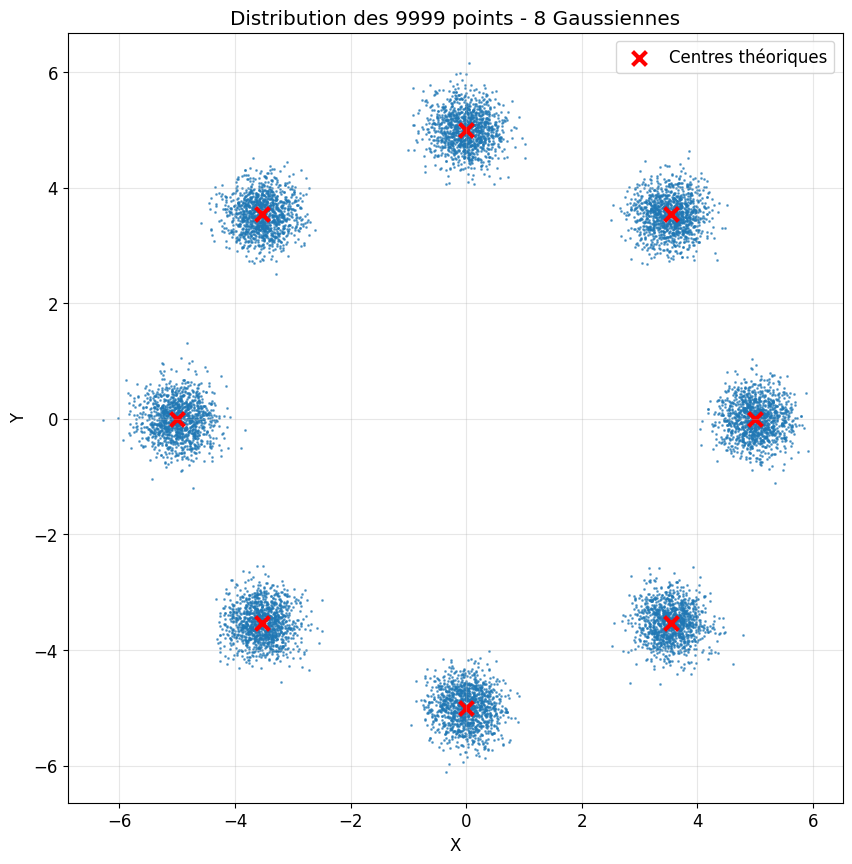

In [14]:
# Configuration de la Gaussian Mixture avec 8 gaussiennes
import torch
from torch.distributions import MultivariateNormal, Categorical

# Paramètres de la configuration
n_samples = 9999
means = torch.tensor([
    [5.0, 0.0],
    [-5.0, 0.0],
    [0.0, 5.0],
    [0.0, -5.0],
    [5 / np.sqrt(2), 5 / np.sqrt(2)],
    [5 / np.sqrt(2), -5 / np.sqrt(2)],
    [-5 / np.sqrt(2), 5 / np.sqrt(2)],
    [-5 / np.sqrt(2), -5 / np.sqrt(2)],
], dtype=torch.float32)

# Écarts-types (variances diagonales)
stds = torch.tensor([
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
    [np.sqrt(0.1), np.sqrt(0.1)],
], dtype=torch.float32)

# Poids uniformes pour les 8 gaussiennes
weights = torch.tensor([1/8] * 8, dtype=torch.float32)

# Création des matrices de covariance (diagonales)
covariances = torch.stack([torch.diag(std**2) for std in stds])

# Distribution catégorielle pour choisir quelle gaussienne
mixture_component = Categorical(weights)

# Distributions gaussiennes multivariées
components = [MultivariateNormal(mean, cov) for mean, cov in zip(means, covariances)]

# Génération des échantillons
def sample_gaussian_mixture(n_samples):
    # Choix des composantes
    component_indices = mixture_component.sample((n_samples,))
    
    # Génération des échantillons
    samples = torch.zeros(n_samples, 2)
    for i in range(8):
        mask = component_indices == i
        n_comp_samples = mask.sum().item()
        if n_comp_samples > 0:
            samples[mask] = components[i].sample((n_comp_samples,))
    
    return samples

# Génération du tenseur de 9999 points
gaussian_mixture_tensor = sample_gaussian_mixture(n_samples)

print(f"Tenseur généré avec succès!")
print(f"Forme: {gaussian_mixture_tensor.shape}")
print(f"Type: {gaussian_mixture_tensor.dtype}")
print(f"Statistiques:")
print(f"  - Moyenne: ({gaussian_mixture_tensor[:, 0].mean():.4f}, {gaussian_mixture_tensor[:, 1].mean():.4f})")
print(f"  - Écart-type: ({gaussian_mixture_tensor[:, 0].std():.4f}, {gaussian_mixture_tensor[:, 1].std():.4f})")
print(f"  - Min: ({gaussian_mixture_tensor[:, 0].min():.4f}, {gaussian_mixture_tensor[:, 1].min():.4f})")
print(f"  - Max: ({gaussian_mixture_tensor[:, 0].max():.4f}, {gaussian_mixture_tensor[:, 1].max():.4f})")

# Visualisation rapide
plt.figure(figsize=(10, 10))
plt.scatter(gaussian_mixture_tensor[:, 0], gaussian_mixture_tensor[:, 1], alpha=0.6, s=1)
plt.title('Distribution des 9999 points - 8 Gaussiennes')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Ajout des centres théoriques
plt.scatter(means[:, 0], means[:, 1], c='red', s=100, marker='x', linewidths=3, label='Centres théoriques')
plt.legend()
plt.show()

## Calcul de la distance de Wasserstein-2

Calcul de la distance de Wasserstein-2 entre le tenseur de référence (8 gaussiennes) et l'étape 61 de la simulation.

POT déjà installé
Nombre d'étapes dans la trajectoire: 61
Index maximum disponible: 60
Forme des données de référence: (9999, 2)
Forme des données étape 61: (9999, 2)
\n=== RÉSULTAT ===
Distance de Wasserstein-2 entre:
  - Tenseur de référence (8 gaussiennes): 9999 points
  - Étape 61 de la simulation: 9999 points
\nDistance de Wasserstein-2: 0.966664
Distance de Wasserstein-2 (racine): 0.983191
\n=== RÉSULTAT ===
Distance de Wasserstein-2 entre:
  - Tenseur de référence (8 gaussiennes): 9999 points
  - Étape 61 de la simulation: 9999 points
\nDistance de Wasserstein-2: 0.966664
Distance de Wasserstein-2 (racine): 0.983191


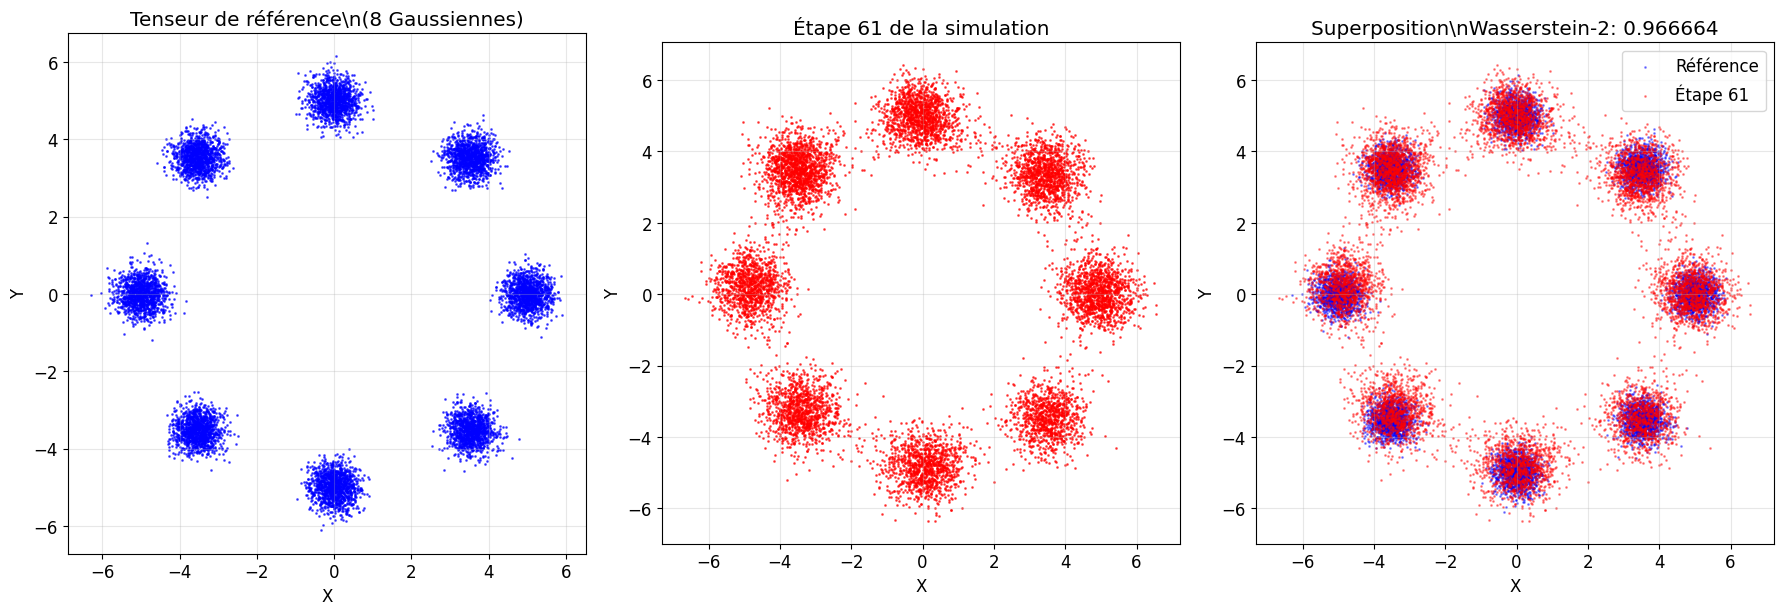

In [15]:
# Installation et import de POT (Python Optimal Transport) pour calculer Wasserstein-2
try:
    import ot
    print("POT déjà installé")
except ImportError:
    print("Installation de POT...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "POT"])
    import ot
    print("POT installé avec succès")

# Vérification que nous avons au moins 61 étapes dans la trajectoire
print(f"Nombre d'étapes dans la trajectoire: {trajectory.shape[0]}")
print(f"Index maximum disponible: {trajectory.shape[0] - 1}")

# L'étape 61 correspond à l'index 60 (indexation à partir de 0)
if trajectory.shape[0] > 60:
    step_61_data = trajectory[60, :, :].numpy()  # Étape 61 (index 60)
    reference_data = gaussian_mixture_tensor.numpy()
    
    print(f"Forme des données de référence: {reference_data.shape}")
    print(f"Forme des données étape 61: {step_61_data.shape}")
    
    # Calcul de la distance de Wasserstein-2
    # Les poids sont uniformes pour les deux distributions
    n_ref = reference_data.shape[0]
    n_step = step_61_data.shape[0]
    
    # Poids uniformes
    weights_ref = np.ones(n_ref) / n_ref
    weights_step = np.ones(n_step) / n_step
    
    # Calcul de la matrice de coût (distances euclidiennes au carré)
    M = ot.dist(reference_data, step_61_data, metric='sqeuclidean')
    
    # Calcul de la distance de Wasserstein-2
    wasserstein_2_distance = ot.emd2(weights_ref, weights_step, M, numItermax=10**7)
    
    print(f"\\n=== RÉSULTAT ===")
    print(f"Distance de Wasserstein-2 entre:")
    print(f"  - Tenseur de référence (8 gaussiennes): {n_ref} points")
    print(f"  - Étape 61 de la simulation: {n_step} points")
    print(f"\\nDistance de Wasserstein-2: {wasserstein_2_distance:.6f}")
    print(f"Distance de Wasserstein-2 (racine): {np.sqrt(wasserstein_2_distance):.6f}")
    
    # Visualisation comparative
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Tenseur de référence
    axes[0].scatter(reference_data[:, 0], reference_data[:, 1], alpha=0.6, s=1, c='blue')
    axes[0].set_title('Tenseur de référence\\n(8 Gaussiennes)')
    axes[0].set_xlabel('X')
    axes[0].set_ylabel('Y')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_aspect('equal')
    
    # Étape 61 de la simulation
    axes[1].scatter(step_61_data[:, 0], step_61_data[:, 1], alpha=0.6, s=1, c='red')
    axes[1].set_title('Étape 61 de la simulation')
    axes[1].set_xlabel('X')
    axes[1].set_ylabel('Y')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_aspect('equal')
    
    # Superposition
    axes[2].scatter(reference_data[:, 0], reference_data[:, 1], alpha=0.4, s=1, c='blue', label='Référence')
    axes[2].scatter(step_61_data[:, 0], step_61_data[:, 1], alpha=0.4, s=1, c='red', label='Étape 61')
    axes[2].set_title(f'Superposition\\nWasserstein-2: {wasserstein_2_distance:.6f}')
    axes[2].set_xlabel('X')
    axes[2].set_ylabel('Y')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    axes[2].set_aspect('equal')
    
    plt.tight_layout()
    plt.show()
    
else:
    print(f"Erreur: La trajectoire n'a que {trajectory.shape[0]} étapes, impossible d'accéder à l'étape 61.")

## Distance W2 entre deux échantillonnages de la même distribution

Calcul de la distance de Wasserstein-2 entre deux tirages indépendants de 9999 points de la même distribution Gaussian Mixture pour mesurer la variabilité intrinsèque.

Génération de deux tirages indépendants de 9999 points...
Premier échantillonnage généré: torch.Size([9999, 2])
Deuxième échantillonnage généré: torch.Size([9999, 2])
\nCalcul de la distance de Wasserstein-2...
\n=== RÉSULTATS - VARIABILITÉ INTRINSÈQUE ===
Distance de Wasserstein-2 entre deux échantillonnages de la même distribution:
  - Premier échantillonnage: 9999 points
  - Deuxième échantillonnage: 9999 points
\nDistance W2 (échantillonnage vs échantillonnage): 0.105957
Distance W2 racine (échantillonnage vs échantillonnage): 0.325510
\n=== COMPARAISON ===
W2 (référence vs simulation étape 61): 0.554648
W2 (échantillonnage 1 vs échantillonnage 2): 0.105957
\nRatio (simulation/variabilité): 5.23
⚠️  La simulation a une erreur supérieure à la variabilité naturelle


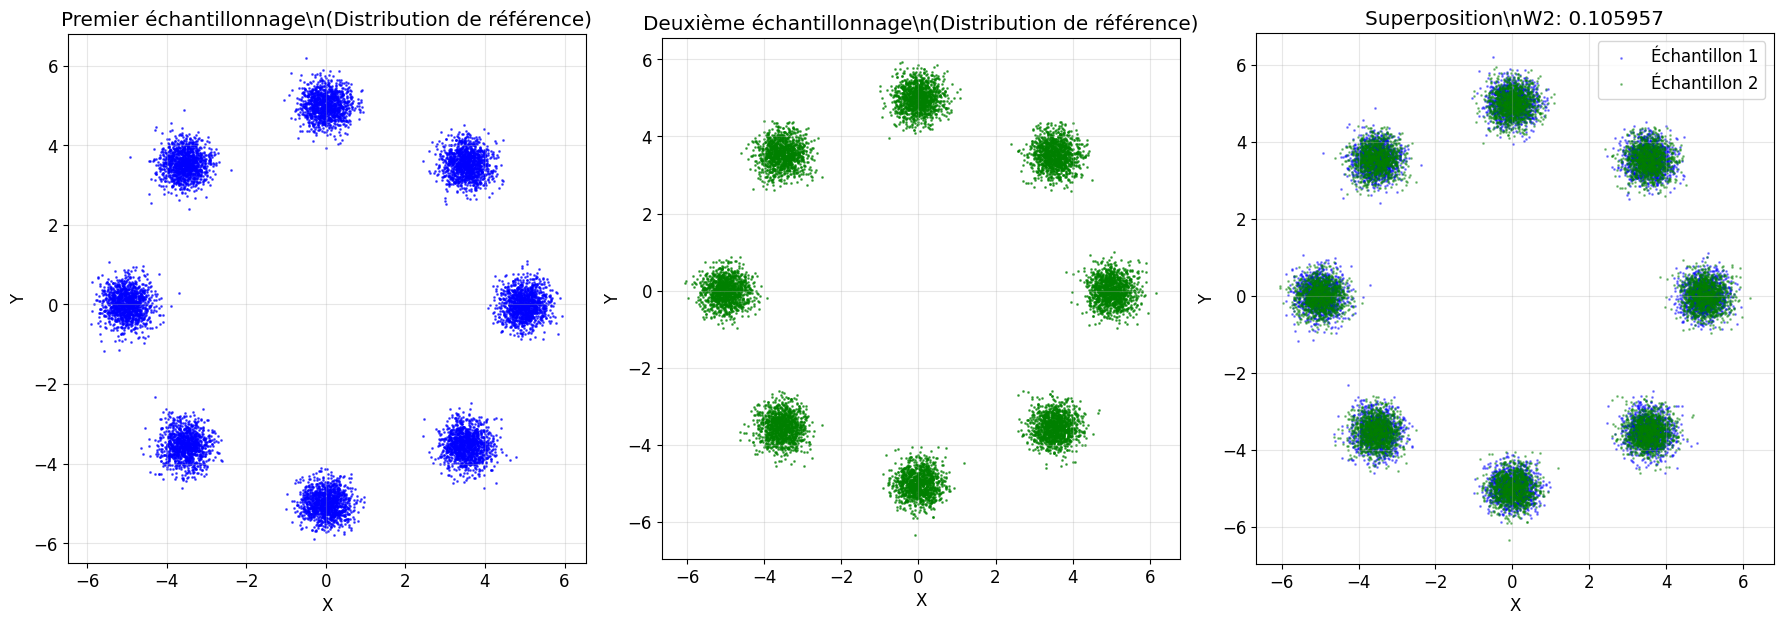

\n=== STATISTIQUES COMPARATIVES ===
Échantillon 1 - Moyenne: (0.0505, 0.0092)
Échantillon 2 - Moyenne: (0.0272, 0.0094)
Échantillon 1 - Std: (3.5549, 3.5448)
Échantillon 2 - Std: (3.5655, 3.5361)


In [11]:
# Génération de deux échantillonnages indépendants de la même distribution
print("Génération de deux tirages indépendants de 9999 points...")

# Premier échantillonnage
sample_1 = sample_gaussian_mixture(9999)
print(f"Premier échantillonnage généré: {sample_1.shape}")

# Deuxième échantillonnage (indépendant)
sample_2 = sample_gaussian_mixture(9999)
print(f"Deuxième échantillonnage généré: {sample_2.shape}")

# Conversion en numpy pour POT
sample_1_np = sample_1.numpy()
sample_2_np = sample_2.numpy()

# Calcul de la distance de Wasserstein-2 entre les deux échantillonnages
print("\\nCalcul de la distance de Wasserstein-2...")

# Poids uniformes pour les deux distributions
n_1 = sample_1_np.shape[0]
n_2 = sample_2_np.shape[0]
weights_1 = np.ones(n_1) / n_1
weights_2 = np.ones(n_2) / n_2

# Calcul de la matrice de coût
M_samples = ot.dist(sample_1_np, sample_2_np, metric='sqeuclidean')

# Calcul de la distance de Wasserstein-2
w2_between_samples = ot.emd2(weights_1, weights_2, M_samples, numItermax=10**7)

print(f"\\n=== RÉSULTATS - VARIABILITÉ INTRINSÈQUE ===")
print(f"Distance de Wasserstein-2 entre deux échantillonnages de la même distribution:")
print(f"  - Premier échantillonnage: {n_1} points")
print(f"  - Deuxième échantillonnage: {n_2} points")
print(f"\\nDistance W2 (échantillonnage vs échantillonnage): {w2_between_samples:.6f}")
print(f"Distance W2 racine (échantillonnage vs échantillonnage): {np.sqrt(w2_between_samples):.6f}")

# Comparaison avec la distance précédente
if 'wasserstein_2_distance' in globals():
    print(f"\\n=== COMPARAISON ===")
    print(f"W2 (référence vs simulation étape 61): {wasserstein_2_distance:.6f}")
    print(f"W2 (échantillonnage 1 vs échantillonnage 2): {w2_between_samples:.6f}")
    print(f"\\nRatio (simulation/variabilité): {wasserstein_2_distance/w2_between_samples:.2f}")
    
    if wasserstein_2_distance < w2_between_samples:
        print("✅ La simulation converge mieux que la variabilité naturelle!")
    else:
        print("⚠️  La simulation a une erreur supérieure à la variabilité naturelle")

# Visualisation comparative
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Premier échantillonnage
axes[0].scatter(sample_1_np[:, 0], sample_1_np[:, 1], alpha=0.6, s=1, c='blue')
axes[0].set_title('Premier échantillonnage\\n(Distribution de référence)')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect('equal')

# Deuxième échantillonnage
axes[1].scatter(sample_2_np[:, 0], sample_2_np[:, 1], alpha=0.6, s=1, c='green')
axes[1].set_title('Deuxième échantillonnage\\n(Distribution de référence)')
axes[1].set_xlabel('X')
axes[1].set_ylabel('Y')
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal')

# Superposition
axes[2].scatter(sample_1_np[:, 0], sample_1_np[:, 1], alpha=0.4, s=1, c='blue', label='Échantillon 1')
axes[2].scatter(sample_2_np[:, 0], sample_2_np[:, 1], alpha=0.4, s=1, c='green', label='Échantillon 2')
axes[2].set_title(f'Superposition\\nW2: {w2_between_samples:.6f}')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].set_aspect('equal')

plt.tight_layout()
plt.show()

# Statistiques comparatives
print(f"\\n=== STATISTIQUES COMPARATIVES ===")
print(f"Échantillon 1 - Moyenne: ({sample_1_np[:, 0].mean():.4f}, {sample_1_np[:, 1].mean():.4f})")
print(f"Échantillon 2 - Moyenne: ({sample_2_np[:, 0].mean():.4f}, {sample_2_np[:, 1].mean():.4f})")
print(f"Échantillon 1 - Std: ({sample_1_np[:, 0].std():.4f}, {sample_1_np[:, 1].std():.4f})")
print(f"Échantillon 2 - Std: ({sample_2_np[:, 0].std():.4f}, {sample_2_np[:, 1].std():.4f})")